# Unit 6 – Creating Agent Dialogues (KQML and KIF)
**Module:** Intelligent Agents (IA_PCOM7E, July 2026) · **Student:** Adil Aljasmi

**Activity brief (Unit 6):** *Create an agent dialogue, using KQML and KIF, between two agents (named Alice and Bob). Alice is an agent designed to procure stock and Bob is an agent that controls the stock levels for a warehouse. This dialogue should see Alice asking Bob about the available stock of 50 inch televisions, and also querying the number of HDMI slots the televisions have.*

**How this notebook is organised**
1. The completed dialogue, written by hand in KQML with KIF content (the answer to the activity).
2. A small Python simulation that sends the same messages between two agents, so the dialogue is shown to be well formed and consistent.
3. Experiments: edge cases (unknown product, malformed message, wrong ontology, stock change, `ask-one` vs `ask-all`).
4. Findings and references.

> **Note:** the warehouse data (model names, stock levels, HDMI counts) are **illustrative values invented for this exercise**, not real products.

## 1. The dialogue

**Shared assumptions (the ontology).** Both agents agree on a small vocabulary called `warehouse-inventory`:

| KIF relation | Meaning |
|---|---|
| `(television ?m)` | `?m` is a television model held in the warehouse |
| `(screen-size ?m ?s)` | model `?m` has a screen diagonal of `?s` inches |
| `(stock-level ?m ?n)` | `?n` units of model `?m` are currently in stock |
| `(hdmi-ports ?m ?n)` | model `?m` has `?n` HDMI slots |

KQML carries the *intention* of each message (the performative, e.g. `ask-all`, `tell`), while KIF carries the *content* (a first-order logic sentence). `:reply-with` / `:in-reply-to` link each answer to its question, and `:language` / `:ontology` tell the receiver how to read the content (Finin et al., 1994; Labrou & Finin, 1997). In KIF, `?x` is a variable and sentences use prefix notation such as `(and …)`, `(exists …)` and `(>= …)` (Genesereth & Fikes, 1992).

**Message 1 – Alice asks which 50-inch televisions are in stock, and how many.**
```lisp
(ask-all
   :sender     Alice
   :receiver   Bob
   :reply-with q1
   :language   KIF
   :ontology   warehouse-inventory
   :content    (and (television ?m)
                    (screen-size ?m 50)
                    (stock-level ?m ?n)))
```
**Message 2 – Bob replies with every matching instance.**
```lisp
(tell
   :sender      Bob
   :receiver    Alice
   :in-reply-to q1
   :language    KIF
   :ontology    warehouse-inventory
   :content     (and (and (television TV50-A) (screen-size TV50-A 50) (stock-level TV50-A 120))
                     (and (television TV50-B) (screen-size TV50-B 50) (stock-level TV50-B 35))))
```
**Message 3 – Alice checks whether at least 100 units of TV50-A are available.**
```lisp
(ask-if
   :sender     Alice
   :receiver   Bob
   :reply-with q2
   :language   KIF
   :ontology   warehouse-inventory
   :content    (exists (?n) (and (stock-level TV50-A ?n) (>= ?n 100))))
```
**Message 4 – Bob confirms the sentence is true in his knowledge base.**
```lisp
(tell
   :sender      Bob
   :receiver    Alice
   :in-reply-to q2
   :language    KIF
   :ontology    warehouse-inventory
   :content     (exists (?n) (and (stock-level TV50-A ?n) (>= ?n 100))))
```
**Message 5 – Alice asks how many HDMI slots TV50-A has.**
```lisp
(ask-one
   :sender     Alice
   :receiver   Bob
   :reply-with q3
   :language   KIF
   :ontology   warehouse-inventory
   :content    (hdmi-ports TV50-A ?p))
```
**Message 6 – Bob answers.**
```lisp
(tell
   :sender      Bob
   :receiver    Alice
   :in-reply-to q3
   :language    KIF
   :ontology    warehouse-inventory
   :content     (hdmi-ports TV50-A 4))
```
**Messages 7–8 – the same question for TV50-B.**
```lisp
(ask-one :sender Alice :receiver Bob :reply-with q4
         :language KIF :ontology warehouse-inventory
         :content (hdmi-ports TV50-B ?p))

(tell    :sender Bob :receiver Alice :in-reply-to q4
         :language KIF :ontology warehouse-inventory
         :content (hdmi-ports TV50-B 3))
```

**Reading the dialogue.** Alice first uses `ask-all` because she wants *every* 50-inch model, not just one. Bob's `tell` lists only 50-inch sets: the 55-inch model he also stocks is filtered out by `(screen-size ?m 50)`. The `ask-if` uses KIF's quantifier and numeric relation to check a procurement threshold without needing the exact figure. The two `ask-one` messages retrieve a single value each. Every reply carries `:in-reply-to` equal to the question's `:reply-with`, so Alice can match answers to questions even if they arrive out of order.

## 2. Simulation: Alice and Bob exchanging the messages
The code below is a minimal, self-contained implementation (standard library only). Bob holds a knowledge base of ground KIF facts and answers `ask-one`, `ask-all` and `ask-if`; Alice sends the scripted questions and checks each reply.

In [1]:
import re, itertools
from dataclasses import dataclass, field

# ---------- KIF / KQML s-expression reading and writing ----------
def tokenize(text):
    return text.replace("(", " ( ").replace(")", " ) ").split()

def read(tokens):
    """Recursive-descent reader for s-expressions; raises SyntaxError on bad brackets."""
    if not tokens:
        raise SyntaxError("unexpected end of message")
    tok = tokens.pop(0)
    if tok == "(":
        out = []
        while tokens and tokens[0] != ")":
            out.append(read(tokens))
        if not tokens:
            raise SyntaxError("missing ')'")
        tokens.pop(0)
        return out
    if tok == ")":
        raise SyntaxError("unexpected ')'")
    # numbers become numbers; symbols are case-insensitive, as in KIF
    return int(tok) if re.fullmatch(r"-?\d+", tok) else tok.lower()

def parse(text):
    tokens = tokenize(text)
    expr = read(tokens)
    if tokens:
        raise SyntaxError("text after the end of the message")
    return expr

def show(expr):
    if isinstance(expr, list):
        return "(" + " ".join(show(e) for e in expr) + ")"
    return str(expr).upper() if isinstance(expr, str) and expr.startswith("tv") else str(expr)

# ---------- KQML message ----------
@dataclass
class KQML:
    performative: str
    params: dict = field(default_factory=dict)

    def __str__(self):
        order = [":sender", ":receiver", ":reply-with", ":in-reply-to", ":language", ":ontology", ":content"]
        parts = [f"{k} {show(self.params[k])}" for k in order if k in self.params]
        return "(" + self.performative + "\n   " + "\n   ".join(parts) + ")"

    @staticmethod
    def from_text(text):
        expr = parse(text)
        if not isinstance(expr, list) or not expr or not isinstance(expr[0], str):
            raise SyntaxError("a KQML message must start with a performative")
        perf, rest = expr[0], expr[1:]
        if len(rest) % 2:
            raise SyntaxError("parameters must come in :keyword value pairs")
        params = {}
        for k, v in zip(rest[::2], rest[1::2]):
            if not (isinstance(k, str) and k.startswith(":")):
                raise SyntaxError(f"expected a :keyword, got {k!r}")
            params[k] = v
        return KQML(perf, params)
print("reader ready")

reader ready


In [2]:
# ---------- a tiny KIF query engine (conjunctions, exists, numeric comparisons) ----------
def is_var(x):
    return isinstance(x, str) and x.startswith("?")

def subst(expr, b):
    if isinstance(expr, list):
        return [subst(e, b) for e in expr]
    return b.get(expr, expr) if is_var(expr) else expr

def unify(pattern, fact, b):
    if len(pattern) != len(fact):
        return None
    b = dict(b)
    for p, f in zip(pattern, fact):
        p = b.get(p, p) if is_var(p) else p
        if is_var(p):
            b[p] = f
        elif p != f:
            return None
    return b

COMPARE = {">": lambda a, c: a > c, ">=": lambda a, c: a >= c,
           "<": lambda a, c: a < c, "=<": lambda a, c: a <= c, "=": lambda a, c: a == c}

def solve(expr, kb, b=None):
    """Yield every binding under which `expr` is true in the knowledge base."""
    b = b or {}
    op = expr[0]
    if op == "and":
        yield from _solve_all(expr[1:], kb, b)
    elif op == "exists":
        variables = expr[1] if isinstance(expr[1], list) else [expr[1]]
        for r in solve(expr[2], kb, b):
            yield {k: v for k, v in r.items() if k not in variables}
    elif op in COMPARE:
        x, y = subst(expr[1], b), subst(expr[2], b)
        if isinstance(x, int) and isinstance(y, int) and COMPARE[op](x, y):
            yield b
    else:
        for fact in kb:
            r = unify(expr, fact, b)
            if r is not None:
                yield r

def _solve_all(conjuncts, kb, b):
    if not conjuncts:
        yield b
        return
    for r in solve(conjuncts[0], kb, b):
        yield from _solve_all(conjuncts[1:], kb, r)

def relations_used(expr):
    if not isinstance(expr, list) or not expr:
        return set()
    head = expr[0]
    if head in ("and", "or", "not"):
        return set().union(*(relations_used(e) for e in expr[1:]))
    if head == "exists":
        return relations_used(expr[2])
    if head in COMPARE:
        return set()
    return {head}
print("KIF engine ready")

KIF engine ready


In [3]:
# ---------- the two agents ----------
ONTOLOGY = "warehouse-inventory"
VOCAB = {"television", "screen-size", "stock-level", "hdmi-ports"}

class Bob:
    """Warehouse stock agent. Answers queries from its own knowledge base (its 'VKB')."""
    def __init__(self, facts):
        self.kb = [parse(f) for f in facts]

    def reply(self, text):
        base = {":sender": "bob", ":language": "kif", ":ontology": ONTOLOGY}
        try:
            msg = KQML.from_text(text)
        except SyntaxError as e:
            # Labrou & Finin (1997): 'error' = the receiver considers the message malformed
            return KQML("error", {**base, ":receiver": "unknown", ":content": f'"{e}"'})
        base[":receiver"] = msg.params.get(":sender", "unknown")
        base[":in-reply-to"] = msg.params.get(":reply-with", "none")
        content = msg.params.get(":content")
        # Bob only understands KIF in the agreed ontology and vocabulary
        if (msg.params.get(":language") != "kif" or msg.params.get(":ontology") != ONTOLOGY
                or not isinstance(content, list) or not relations_used(content) <= VOCAB):
            return KQML("error", {**base, ":content": '"unknown language, ontology or relation"'})
        answers = list(solve(content, self.kb))
        if msg.performative == "ask-one":
            if not answers:   # understood, but nothing more informative to say
                return KQML("sorry", base)
            return KQML("tell", {**base, ":content": subst(content, answers[0])})
        if msg.performative == "ask-all":
            if not answers:
                return KQML("sorry", base)
            seen = []
            for a in answers:
                inst = subst(content, a)
                if inst not in seen:
                    seen.append(inst)
            return KQML("tell", {**base, ":content": ["and", *seen] if len(seen) > 1 else seen[0]})
        if msg.performative == "ask-if":
            # tell = sentence is in Bob's VKB; untell = it is not (Labrou & Finin, 1997)
            return KQML("tell" if answers else "untell", {**base, ":content": content})
        return KQML("sorry", base)

class Alice:
    """Procurement agent. Sends questions and matches each reply to its question."""
    def __init__(self):
        self.counter = itertools.count(1)
        self.pending = {}

    def ask(self, performative, content, ontology=ONTOLOGY, language="kif"):
        qid = f"q{next(self.counter)}"
        self.pending[qid] = content
        return (f"({performative} :sender alice :receiver bob :reply-with {qid} "
                f":language {language} :ontology {ontology} :content {content})")

    def receive(self, msg):
        qid = msg.params.get(":in-reply-to")
        matched = self.pending.pop(qid, None) is not None
        return matched

WAREHOUSE = [  # illustrative values only
    "(television tv50-a)", "(screen-size tv50-a 50)", "(stock-level tv50-a 120)", "(hdmi-ports tv50-a 4)",
    "(television tv50-b)", "(screen-size tv50-b 50)", "(stock-level tv50-b 35)",  "(hdmi-ports tv50-b 3)",
    "(television tv55-c)", "(screen-size tv55-c 55)", "(stock-level tv55-c 40)",  "(hdmi-ports tv55-c 4)",
]
print(f"Bob's knowledge base holds {len(WAREHOUSE)} facts about 3 models.")

Bob's knowledge base holds 12 facts about 3 models.


In [4]:
LOG = []   # (sender, receiver, performative, id) for the sequence diagram

def exchange(alice, bob, performative, content, **kw):
    out = alice.ask(performative, content, **kw)
    sent = KQML.from_text(out)
    LOG.append(("Alice", "Bob", performative, sent.params[":reply-with"]))
    print(">>> Alice -> Bob\n" + str(sent))
    ans = bob.reply(out)
    LOG.append(("Bob", "Alice", ans.performative, ans.params.get(":in-reply-to")))
    print("<<< Bob -> Alice\n" + str(ans))
    print("    reply matched to question:", alice.receive(ans), "\n")
    return ans

alice, bob = Alice(), Bob(WAREHOUSE)
r1 = exchange(alice, bob, "ask-all", "(and (television ?m) (screen-size ?m 50) (stock-level ?m ?n))")
r2 = exchange(alice, bob, "ask-if",  "(exists (?n) (and (stock-level tv50-a ?n) (>= ?n 100)))")
r3 = exchange(alice, bob, "ask-one", "(hdmi-ports tv50-a ?p)")
r4 = exchange(alice, bob, "ask-one", "(hdmi-ports tv50-b ?p)")

>>> Alice -> Bob
(ask-all
   :sender alice
   :receiver bob
   :reply-with q1
   :language kif
   :ontology warehouse-inventory
   :content (and (television ?m) (screen-size ?m 50) (stock-level ?m ?n)))
<<< Bob -> Alice
(tell
   :sender bob
   :receiver alice
   :in-reply-to q1
   :language kif
   :ontology warehouse-inventory
   :content (and (and (television TV50-A) (screen-size TV50-A 50) (stock-level TV50-A 120)) (and (television TV50-B) (screen-size TV50-B 50) (stock-level TV50-B 35))))
    reply matched to question: True 

>>> Alice -> Bob
(ask-if
   :sender alice
   :receiver bob
   :reply-with q2
   :language kif
   :ontology warehouse-inventory
   :content (exists (?n) (and (stock-level TV50-A ?n) (>= ?n 100))))
<<< Bob -> Alice
(tell
   :sender bob
   :receiver alice
   :in-reply-to q2
   :language kif
   :ontology warehouse-inventory
   :content (exists (?n) (and (stock-level TV50-A ?n) (>= ?n 100))))
    reply matched to question: True 

>>> Alice -> Bob
(ask-one
   :sender

In [5]:
# Summarise what Alice learned from the main dialogue
models = [c for c in r1.params[":content"][1:]] if r1.params[":content"][0] == "and" and isinstance(r1.params[":content"][1], list) and r1.params[":content"][1][0] == "and" else [r1.params[":content"]]
stock = {c[3][1]: c[3][2] for c in models}
hdmi = {r.params[":content"][1]: r.params[":content"][2] for r in (r3, r4)}
print("50-inch models in stock:", {k.upper(): v for k, v in stock.items()})
print("Total 50-inch units    :", sum(stock.values()))
print("HDMI slots             :", {k.upper(): v for k, v in hdmi.items()})
print("At least 100 TV50-A?   :", r2.performative == "tell")
print("Messages exchanged     :", len(LOG))

50-inch models in stock: {'TV50-A': 120, 'TV50-B': 35}
Total 50-inch units    : 155
HDMI slots             : {'TV50-A': 4, 'TV50-B': 3}
At least 100 TV50-A?   : True
Messages exchanged     : 8


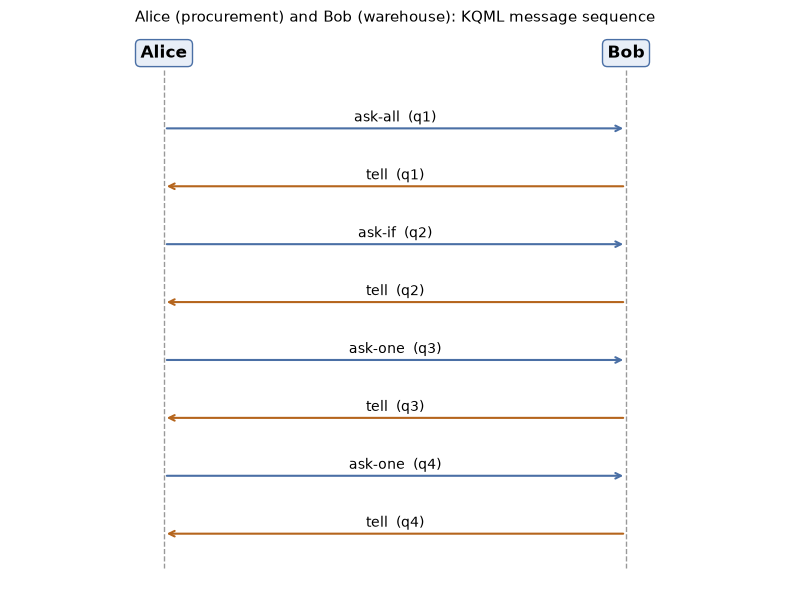

In [6]:
import matplotlib.pyplot as plt

def sequence_diagram(log, title, path):
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(log) + 1.6))
    xs = {"Alice": 0.2, "Bob": 0.8}
    n = len(log)
    for name, x in xs.items():
        ax.text(x, n + 0.6, name, ha="center", va="center", fontsize=12, weight="bold",
                bbox=dict(boxstyle="round", fc="#e8eef7", ec="#4a6fa5"))
        ax.plot([x, x], [n + 0.3, -0.3], color="#999", ls="--", lw=1)
    for i, (s, r, perf, qid) in enumerate(log):
        y = n - 1 - i + 0.3
        ax.annotate("", xy=(xs[r], y), xytext=(xs[s], y),
                    arrowprops=dict(arrowstyle="->", color="#4a6fa5" if s == "Alice" else "#b5651d", lw=1.5))
        ax.text(0.5, y + 0.12, f"{perf}  ({qid})", ha="center", fontsize=10)
    ax.set_xlim(0, 1); ax.set_ylim(-0.5, n + 1); ax.axis("off")
    ax.set_title(title, fontsize=11)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

sequence_diagram(LOG, "Alice (procurement) and Bob (warehouse): KQML message sequence",
                 "6.Unit06 Alice-Bob KQML sequence diagram.png")

## 3. Experiments
Each experiment changes one thing and records how Bob responds.

In [7]:
def quick(performative, content, bob_agent, **kw):
    a = Alice()
    ans = bob_agent.reply(a.ask(performative, content, **kw))
    return ans.performative, show(ans.params.get(":content", ""))

results = []
# E1: a model Bob does not stock -> understood but no answer -> sorry
results.append(("E1 unknown model (TV65-X)", *quick("ask-one", "(hdmi-ports tv65-x ?p)", bob)))
# E2: malformed message (missing bracket) -> error
results.append(("E2 malformed message", bob.reply("(ask-one :sender alice :content (hdmi-ports tv50-a ?p)").performative, ""))
# E3: same question in a different ontology -> error (Bob cannot interpret the content)
results.append(("E3 wrong ontology 'retail-catalogue'", *quick("ask-one", "(hdmi-ports tv50-a ?p)", bob, ontology="retail-catalogue")))
# E4: relation outside the shared vocabulary -> error
results.append(("E4 unknown relation (hdmi-slots)", *quick("ask-one", "(hdmi-slots tv50-a ?p)", bob)))
# E5: ask-one vs ask-all on the same content
results.append(("E5a ask-one, 50-inch stock", *quick("ask-one", "(and (screen-size ?m 50) (stock-level ?m ?n))", bob)))
results.append(("E5b ask-all, 50-inch stock", *quick("ask-all", "(and (screen-size ?m 50) (stock-level ?m ?n))", bob)))
# E6: threshold that is not met -> untell
results.append(("E6 ask-if TV50-B >= 100", *quick("ask-if", "(exists (?n) (and (stock-level tv50-b ?n) (>= ?n 100)))", bob)))
for name, perf, content in results:
    print(f"{name:<38} -> {perf:<7} {content}")

E1 unknown model (TV65-X)              -> sorry   
E2 malformed message                   -> error   
E3 wrong ontology 'retail-catalogue'   -> error   "unknown language, ontology or relation"
E4 unknown relation (hdmi-slots)       -> error   "unknown language, ontology or relation"
E5a ask-one, 50-inch stock             -> tell    (and (screen-size TV50-A 50) (stock-level TV50-A 120))
E5b ask-all, 50-inch stock             -> tell    (and (and (screen-size TV50-A 50) (stock-level TV50-A 120)) (and (screen-size TV50-B 50) (stock-level TV50-B 35)))
E6 ask-if TV50-B >= 100                -> untell  (exists (?n) (and (stock-level TV50-B ?n) (>= ?n 100)))


In [8]:
# E7: stock changes between two identical questions (e.g. Bob ships 90 units of TV50-A)
bob2 = Bob(WAREHOUSE)
before = quick("ask-if", "(exists (?n) (and (stock-level tv50-a ?n) (>= ?n 100)))", bob2)
bob2.kb = [f if f[:2] != ["stock-level", "tv50-a"] else ["stock-level", "tv50-a", 30] for f in bob2.kb]
after = quick("ask-if", "(exists (?n) (and (stock-level tv50-a ?n) (>= ?n 100)))", bob2)
print("Before shipment:", before[0], "| after shipment:", after[0])
print("New stock reply:", quick("ask-one", "(stock-level tv50-a ?n)", bob2))

# E8: reply matching - answers arriving in reverse order are still matched by :in-reply-to
a = Alice()
qs = [a.ask("ask-one", "(hdmi-ports tv50-a ?p)"), a.ask("ask-one", "(hdmi-ports tv50-b ?p)")]
replies = [bob.reply(q) for q in qs][::-1]
print("Reverse-order replies matched:", [ (r.params[':in-reply-to'], a.receive(r)) for r in replies ])

Before shipment: tell | after shipment: untell
New stock reply: ('tell', '(stock-level TV50-A 30)')
Reverse-order replies matched: [('q2', True), ('q1', True)]


## 4. Findings

**What the dialogue shows.** Alice's `ask-all` returned two 50-inch models, TV50-A (120 units) and TV50-B (35 units), 155 units in total, and correctly left out the 55-inch TV55-C. The `ask-if` confirmed that at least 100 units of TV50-A are available, and the two `ask-one` questions returned 4 HDMI slots for TV50-A and 3 for TV50-B. The full exchange took 8 messages. *(All stock figures are invented for the exercise.)*

**What the experiments show.**
- **Different failures need different replies.** An unknown model (E1) gave `sorry`: Bob understood the question but had nothing to tell. A broken message (E2), a different ontology (E3) and an unknown relation name such as `hdmi-slots` instead of `hdmi-ports` (E4) gave `error`, because Bob could not interpret them. E4 is the most realistic risk: two agents can share KQML and KIF and still fail if their vocabularies differ, which is why the `:ontology` parameter matters (Finin et al., 1994).
- **`ask-one` vs `ask-all`.** On the same content, `ask-one` returned only the first 50-inch model, while `ask-all` returned both (E5). A procurement agent that used `ask-one` here would underestimate the available stock.
- **Negative answers.** For a threshold that is not met (E6), Bob replied `untell`, meaning the sentence is not in his knowledge base, rather than staying silent.
- **Answers are snapshots.** After 90 units were shipped (E7), the same `ask-if` changed from `tell` to `untell`. A `tell` reports what Bob believes at that moment. If Alice needs to be told about changes, `subscribe` (Labrou & Finin, 1997) would suit better than repeated polling.
- **Matching replies.** Replies sent in reverse order were still matched to the right questions through `:in-reply-to` (E8).

**Reflection.** Writing the messages was quick, but the simulation exposed decisions that a hand-written dialogue hides: which performative to use when a product is unknown, how to reply to a false `ask-if`, and how exactly both agents must name relations. This links to my Discussion 2 point that ACL semantics are hard to check from outside (Singh, 1998): the protocol fixes the message form, but the meaning still depends on a shared ontology. It also mirrors our ScholarPlan design, where JSON schemas played the role of the content language.

## References
Finin, T., Fritzson, R., McKay, D. & McEntire, R. (1994) KQML as an agent communication language. *Proceedings of the Third International Conference on Information and Knowledge Management (CIKM '94)*. Gaithersburg, Maryland. New York: ACM. 456–463.

Genesereth, M.R. & Fikes, R.E. (eds.) (1992) *Knowledge Interchange Format, Version 3.0 Reference Manual*. Technical Report Logic-92-1. Stanford, CA: Computer Science Department, Stanford University.

Labrou, Y. & Finin, T. (1997) *A Proposal for a new KQML Specification*. Technical Report TR CS-97-03. Baltimore, MD: University of Maryland Baltimore County.

Singh, M.P. (1998) Agent communication languages: Rethinking the principles. *Computer* 31(12): 40–47.

Wooldridge, M. (2009) *An Introduction to MultiAgent Systems*. 2nd ed. Chichester: John Wiley & Sons.